# Peak-VRAM model: measure, don't assume

Earlier notebooks estimated peak GPU memory as **2 × rollout-buffer size + 2 GB**
— both constants were guesses. This notebook fits them instead:

$$\text{peak VRAM} \approx a \cdot \underbrace{(T \cdot N_\text{env} \cdot |o| \cdot 4\,\text{bytes})}_{x,\ \text{the rollout buffer}} + b$$

with $T$ the PPO horizon (24 for both pipelines), $N_\text{env}$ the parallel
env count, and $|o|$ the per-env observation floats stored per step
(camera $3k \cdot H \cdot W$ + the critic's 28-float state; feature-vector 28).

**Method** (`experiments/memory_probe.py`):

- Each config runs in a **fresh process** (genesis allows one backend per
  process, and `gs.init` mutates the torch default device — P17), for a few
  PPO updates only: peak memory lands after the first rollout + update.
- Two meters per run: `torch.cuda.max_memory_allocated()` (what PyTorch sees,
  incl. the rollout buffer) and a **per-PID** `nvidia-smi` polling thread (the
  whole process: renderer, Madrona's 1 GiB device heap, CUDA context). The gap
  between them is what $b$ is made of. Per-PID means another resident
  (e.g. ollama) never contaminates a reading.
- A **free-VRAM guard** skips any config that wouldn't fit the card right now;
  skipped configs stay pending and a later run picks them up. Results are
  cached as JSON, so re-running this notebook only measures what's missing.

**Grid** — sized for this machine (16 GB RTX 4060 Ti, sometimes shared): the
camera points span each axis ($N_\text{env}$, frame stack $k$, resolution at
1× and 2×) up to $x \approx 2.8$ GiB rather than the full 24-point cross — a
2-parameter line doesn't need it, and three *distinct* configs deliberately
share $x \approx 1.42$ GiB: if $x$ alone predicts memory, their peaks must
agree, which tests the multiplicative claim directly. Feature-vector points
(up to 8192 envs) pin the no-renderer intercept.

**G4 grid** (`CARD = "g4"`, Colab RTX PRO 6000, 96 GB): every line gets 5–6
points, doubling $N_\text{env}$ until the 16 GB fit predicts ~76 GiB, so each
family's top point probes the big card's ceiling. Results land in
`runs/memory_model_g4/`; how to run Madrona on Colab is in genesis's
`docs/usage/google_colab_cli.md`.


In [1]:
import json
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "experiments").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from experiments.memory_probe import (GRIDS, HORIZON, config_name,
                                      predicted_bytes)

#: card profile: "4060ti" (local 16 GB) or "g4" (Colab RTX PRO 6000, 96 GB)
CARD = "4060ti"
GRID = GRIDS[CARD]
OUT = ROOT / "runs" / ("memory_model" if CARD == "4060ti"
                       else f"memory_model_{CARD}")
GiB = 2**30

grid = pd.DataFrame([{**c, "name": config_name(c),
                      "x_GiB": predicted_bytes(c) / GiB} for c in GRID])
grid.fillna({"frame_stack": "-", "res_scale": "-"})


def save_atomic(fig, path, **kw):
    """Write the figure to a temp file, then rename: a viewer watching the
    PNG never sees a half-written file."""
    import os
    tmp = str(path) + ".tmp"
    fig.savefig(tmp, format="png", **kw)
    os.replace(tmp, path)


## Run the grid

One subprocess per missing config (~15–60 s each cold; cached ones are free).
Progress streams below. Free as much VRAM as you can first — e.g.
`ollama stop` — so the guard doesn't skip the large points.


In [2]:
proc = subprocess.run(
    [sys.executable, str(ROOT / "experiments" / "memory_probe.py"),
     "--sweep", str(OUT), "--grid", CARD])
assert proc.returncode == 0

rows = [json.loads(p.read_text()) for p in sorted(OUT.glob("*.json"))]
df = pd.DataFrame([{
    "name": r["name"], "modality": r["config"]["modality"],
    "x_GiB": r["x_bytes"] / GiB,
    "torch_GiB": r.get("torch_peak_bytes", np.nan) / GiB,
    "proc_GiB": r.get("proc_peak_bytes", np.nan) / GiB,
    "ok": r["ok"], "error": r.get("error", ""),
} for r in rows]).sort_values(["modality", "x_GiB"], ignore_index=True)

pending = {config_name(c) for c in GRID} - set(df["name"])
if pending:
    print(f"still pending (skipped by the VRAM guard?): {sorted(pending)}")
df


[sweep] cam_N32_k1_r1: cached
[sweep] cam_N64_k1_r1: cached
[sweep] cam_N128_k1_r1: cached
[sweep] cam_N256_k1_r1: cached
[sweep] cam_N64_k2_r1: cached
[sweep] cam_N64_k4_r1: cached
[sweep] cam_N32_k4_r1: cached
[sweep] cam_N64_k2_r2: cached
[sweep] cam_N128_k2_r1: cached
[sweep] cam_N256_k2_r1: cached
[sweep] cam_N384_k2_r1: cached
[sweep] cam_N448_k2_r1: cached
[sweep] cam_N32_k1_r2: cached
[sweep] cam_N64_k1_r2: cached
[sweep] cam_N32_k2_r2: cached
[sweep] feat_N1024: cached
[sweep] feat_N4096: cached
[sweep] feat_N8192: cached
[sweep] collect_N32: cached
[sweep] collect_N64: cached
[sweep] collect_N128: cached
[sweep] collect_N256: cached
[sweep] collect_N512: cached
[sweep] collect_N1024: cached
[sweep] collect_N2048: cached
[sweep] collect_N4096: cached
[sweep] collect_N256_r2: cached
[sweep] collect_N512_r2: cached
[sweep] collect_N1024_r2: cached


,name,modality,x_GiB,torch_GiB,proc_GiB,ok,error
0,cam_N32_k1_r1,camera,0.164875,0.424915,2.463867,True,
1,cam_N64_k1_r1,camera,0.329750,0.741883,2.815430,True,
2,cam_N32_k1_r2,camera,0.659260,1.772686,4.057617,True,
3,cam_N32_k4_r1,camera,0.659260,1.191960,3.641602,True,
4,cam_N64_k2_r1,camera,0.659340,1.271667,3.530273,True,
5,cam_N128_k1_r1,camera,0.659500,1.377138,3.704102,True,
6,cam_N32_k2_r2,camera,1.318439,2.771845,5.559570,True,
7,cam_N64_k1_r2,camera,1.318520,3.068214,5.977539,True,
8,cam_N64_k4_r1,camera,1.318520,2.278708,4.608398,True,
9,cam_N128_k2_r1,camera,1.318680,2.430268,5.034180,True,


## Fit $a$ and $b$

Least squares on the camera grid, once per meter. The process-level fit is
the number that matters for "will it fit on the card"; the torch-only fit
shows how much of $b$ PyTorch even sees.


In [3]:
cam = df[(df.modality == "camera") & df.ok]
assert len(cam) >= 3, "need at least 3 successful camera points to fit"

def fit(y_gib):
    A = np.stack([cam.x_GiB.to_numpy(), np.ones(len(cam))], axis=1)
    (a, b), *_ = np.linalg.lstsq(A, y_gib.to_numpy(), rcond=None)
    pred = a * cam.x_GiB + b
    max_rel_err = float((np.abs(pred - y_gib) / y_gib).max())
    return a, b, max_rel_err

a, b, err = fit(cam.proc_GiB)
a_t, b_t, err_t = fit(cam.torch_GiB)
feat = df[(df.modality == "feature") & df.ok]

print(f"process-level:  peak ≈ {a:.2f}·x + {b:.2f} GiB   "
      f"(max rel. error {err:.1%})")
print(f"torch-only:     peak ≈ {a_t:.2f}·x + {b_t:.2f} GiB   "
      f"(max rel. error {err_t:.1%})")
print(f"non-torch overhead (renderer + Madrona heap + context): "
      f"b − b_torch ≈ {b - b_t:.2f} GiB")
if len(feat):
    print(f"feature-vector baseline (no renderer): "
          f"{feat.proc_GiB.iloc[0]:.2f} GiB at {feat.name.iloc[0]}")

cluster = cam.x_GiB.round(2).mode().iloc[0]
same_x = cam[np.isclose(cam.x_GiB, cluster, rtol=0.05)]
if len(same_x) > 1:
    spread = same_x.proc_GiB.max() - same_x.proc_GiB.min()
    print(f"equal-x configs ({', '.join(same_x.name)}): "
          f"peak spread {spread:.2f} GiB — x-only claim "
          + ("holds" if spread < 0.15 * same_x.proc_GiB.mean() else "STRAINED"))

print()
print(f"Thesis sentence: peak training memory follows "
      f"{a:.1f}·(T·N·|o|·4 B) + {b:.1f} GiB to within {err:.0%} "
      f"across the measured grid.")


process-level:  peak ≈ 2.34·x + 2.15 GiB   (max rel. error 13.6%)
torch-only:     peak ≈ 1.74·x + 0.28 GiB   (max rel. error 32.7%)
non-torch overhead (renderer + Madrona heap + context): b − b_torch ≈ 1.87 GiB
feature-vector baseline (no renderer): 1.57 GiB at feat_N8192
equal-x configs (cam_N32_k2_r2, cam_N64_k1_r2, cam_N64_k4_r1, cam_N128_k2_r1, cam_N256_k1_r1): peak spread 1.37 GiB — x-only claim STRAINED

Thesis sentence: peak training memory follows 2.3·(T·N·|o|·4 B) + 2.2 GiB to within 14% across the measured grid.


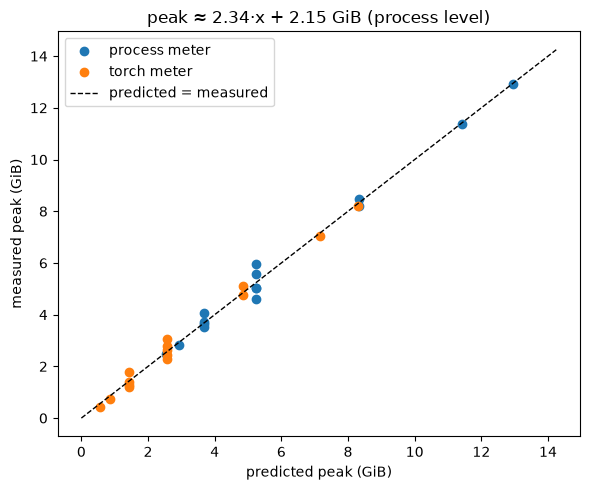

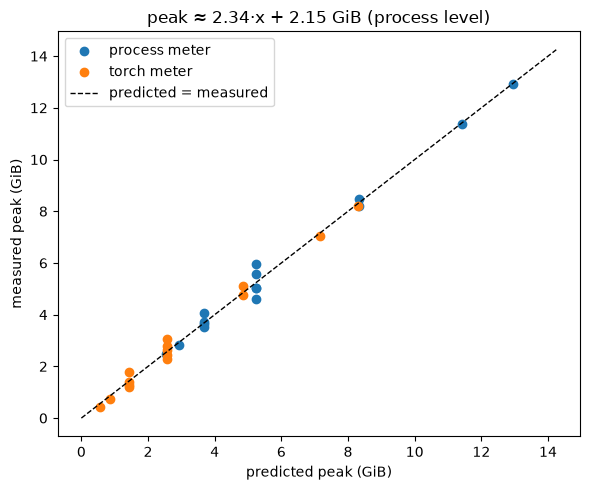

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 5))
for meter, (aa, bb), color in (("process", (a, b), "tab:blue"),
                               ("torch", (a_t, b_t), "tab:orange")):
    y = cam.proc_GiB if meter == "process" else cam.torch_GiB
    ax.scatter(aa * cam.x_GiB + bb, y, label=f"{meter} meter", color=color)
lo, hi = 0, max(cam.proc_GiB.max(), (a * cam.x_GiB + b).max()) * 1.1
ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="predicted = measured")
ax.set_xlabel("predicted peak (GiB)")
ax.set_ylabel("measured peak (GiB)")
ax.set_title(f"peak ≈ {a:.2f}·x + {b:.2f} GiB (process level)")
ax.legend()
fig.tight_layout()
save_atomic(fig, OUT / "memory_model_fit.png", dpi=150)
fig


## Feature vector vs camera vs dataset collection

The same measurements, read as a comparison: every bar is one config's peak
process memory, split into what PyTorch sees (rollout buffer + networks) and
the overhead PyTorch doesn't (renderer, Madrona's device heap, CUDA context).
CNN-dataset collection sits between the pipelines: camera renderer, no
training. Its footprint is overhead-dominated and cheap below ~512 envs, but
the renderer's per-env buffers take over at scale — roughly doubling per
doubling past 1024 envs, to 9.5 GiB at 4096. The per-env column is the
punchline: collection converges to ~2.4 MiB/env, an order of magnitude under
camera *training* at the same env counts.


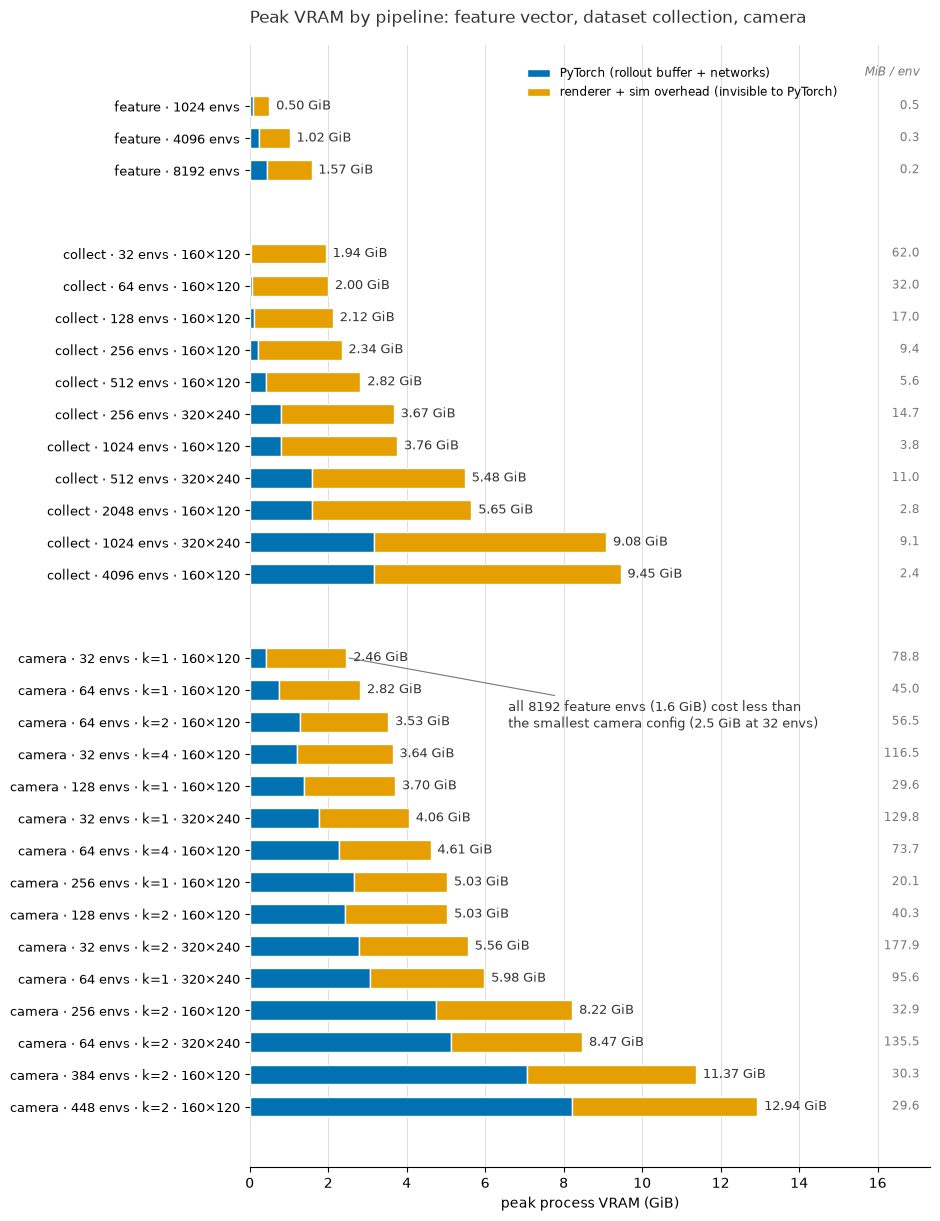

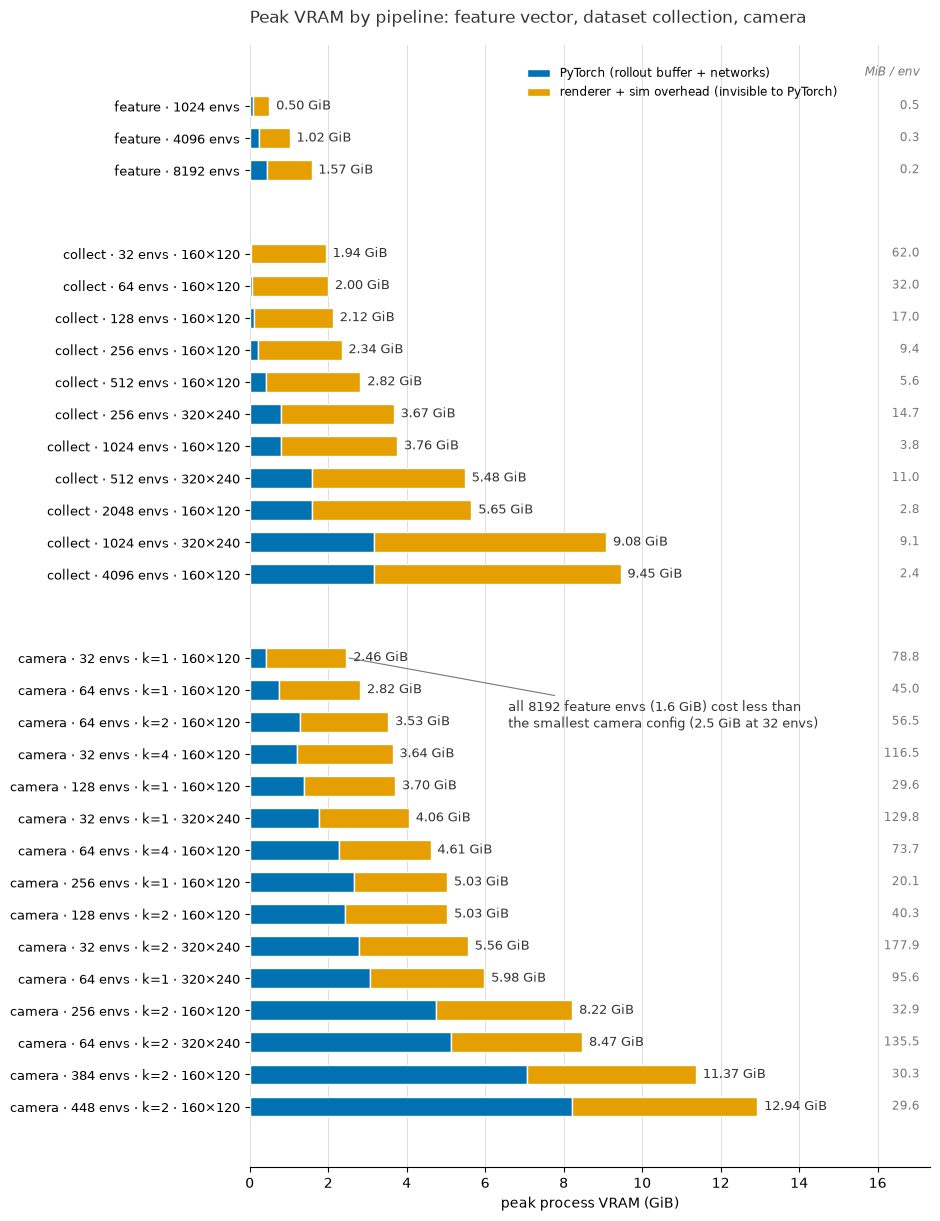

In [5]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#0072B2", "#E69F00"     # CVD-validated pair
INK, MUTED = "#333333", "#777777"
GROUP = {"feature": 0, "collect": 1, "camera": 2}

recs = []
for r in rows:
    if not r["ok"]:
        continue
    c = r["config"]
    if c["modality"] == "feature":
        lab = f"feature · {c['num_envs']} envs"
    elif c["modality"] == "collect":
        w, h = 160 * c["res_scale"], 120 * c["res_scale"]
        lab = f"collect · {c['num_envs']} envs · {w}×{h}"
    else:
        w, h = 160 * c["res_scale"], 120 * c["res_scale"]
        lab = f"camera · {c['num_envs']} envs · k={c['frame_stack']} · {w}×{h}"
    recs.append({"label": lab, "modality": c["modality"],
                 "envs": c["num_envs"],
                 "torch": r["torch_peak_bytes"] / GiB,
                 "total": r["proc_peak_bytes"] / GiB})
recs.sort(key=lambda r: (GROUP[r["modality"]], r["total"]))

GAP = 1.6                                # blank band between groups
ys, y = [], 0.0
for i, r in enumerate(recs):
    if i and recs[i - 1]["modality"] != r["modality"]:
        y += GAP
    ys.append(y)
    y += 1.0

xmax = max(r["total"] for r in recs) * 1.34
fig, ax = plt.subplots(figsize=(9.5, 0.36 * (ys[-1] + 3)))
for r, yy in zip(recs, ys):
    ax.barh(yy, r["torch"], height=0.62, color=BLUE,
            edgecolor="white", linewidth=1)
    ax.barh(yy, r["total"] - r["torch"], left=r["torch"], height=0.62,
            color=ORANGE, edgecolor="white", linewidth=1)
    ax.text(r["total"] + xmax * 0.01, yy, f"{r['total']:.2f} GiB",
            va="center", fontsize=9, color=INK)
    ax.text(xmax * 0.985, yy, f"{r['total'] * 1024 / r['envs']:,.1f}",
            va="center", ha="right", fontsize=8.5, color=MUTED)
ax.text(xmax * 0.985, -0.95, "MiB / env", ha="right", fontsize=8.5,
        color=MUTED, style="italic")

ax.set_yticks(ys)
ax.set_yticklabels([r["label"] for r in recs], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, xmax)
ax.set_xlabel("peak process VRAM (GiB)")
ax.xaxis.grid(True, color="#DDDDDD", linewidth=0.7)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)

first_cam = next(i for i, r in enumerate(recs) if r["modality"] == "camera")
ax.annotate("all 8192 feature envs (1.6 GiB) cost less than\n"
            f"the smallest camera config "
            f"({recs[first_cam]['total']:.1f} GiB at 32 envs)",
            xy=(recs[first_cam]["total"], ys[first_cam]),
            xytext=(xmax * 0.38, ys[first_cam] + 1.8), fontsize=9, color=INK,
            va="center",
            arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.8})
ax.legend(["PyTorch (rollout buffer + networks)",
           "renderer + sim overhead (invisible to PyTorch)"],
          loc="upper right", bbox_to_anchor=(0.88, 0.99),
          fontsize=8.5, frameon=False)
ax.set_title("Peak VRAM by pipeline: feature vector, dataset collection, camera",
             fontsize=12, color=INK, loc="left", pad=16)
fig.tight_layout()
save_atomic(fig, OUT / "memory_feature_vs_camera.png", dpi=150,
            bbox_inches="tight")
fig


### PyTorch memory vs parallel envs

The renderer overhead above is a fixed tax; this view strips it and plots only
what **training itself** allocates (`torch.cuda.max_memory_allocated`). One
line per camera configuration family — darker orange = more observation bytes
per env — plus the feature vector and CNN-dataset collection. Collection
stays low: no PPO, so its torch share is just the observation tensors, and
its real footprint (previous figure) is renderer overhead that only bites
past ~1024 envs. Note the two 4×-obs families (k=4 at 160×120 vs k=1 at
320×240): identical rollout bytes, yet the high-resolution line sits higher —
render-output buffers scale with resolution alone, the same effect straining
the equal-x check in the fit.


In [6]:
GREEN = "#009E73"                       # feature vector
BLUES = {1: "#56B4E9", 2: "#0072B2"}    # collection 1x / 2x (validated)
#: camera families, ordered by obs-size multiplier -> sequential ramp
FAMILIES = [((1, 1), "#FD8D3C", "k=1 · 160×120  (1×)"),
            ((2, 1), "#F16913", "k=2 · 160×120  (2×)"),
            ((4, 1), "#D94801", "k=4 · 160×120  (4×)"),
            ((1, 2), "#A63603", "k=1 · 320×240  (4×)"),
            ((2, 2), "#7F2704", "k=2 · 320×240  (8×)")]
INK, MUTED = "#333333", "#777777"


def series_by_family(meter):
    """Group successful runs into (envs, GiB) lines for one memory meter."""
    cam_pts, feat_pts, coll_pts = {}, [], {}
    for r in rows:
        if not r["ok"]:
            continue
        c, t = r["config"], r[meter] / GiB
        if c["modality"] == "feature":
            feat_pts.append((c["num_envs"], t))
        elif c["modality"] == "collect":
            coll_pts.setdefault(c["res_scale"], []).append((c["num_envs"], t))
        else:
            cam_pts.setdefault((c["frame_stack"], c["res_scale"]), []).append(
                (c["num_envs"], t))
    return ({k: sorted(v) for k, v in cam_pts.items()}, sorted(feat_pts),
            {k: sorted(v) for k, v in coll_pts.items()})


def plot_lines(meter, ylabel, title, fname, capacity_gib=None):
    """One line per pipeline family against env count (log2 x axis)."""
    cam_pts, feat_pts, coll_pts = series_by_family(meter)
    lines = ([(cam_pts.get(key, []), color, label)
              for key, color, label in FAMILIES]
             + [(feat_pts, GREEN, "feature vector")]
             + [(series, BLUES[rs], f"collection · {160 * rs}×{120 * rs}")
                for rs, series in sorted(coll_pts.items())])
    lines = [line for line in lines if line[0]]

    fig, ax = plt.subplots(figsize=(9.5, 6))
    for series, color, label in lines:
        ax.plot(*zip(*series), "-o", color=color, linewidth=2, markersize=6.5,
                label=label)
    if capacity_gib:
        ax.axhline(capacity_gib, color=MUTED, linewidth=1, linestyle="--")
        ax.annotate(f"card capacity — {capacity_gib:.0f} GiB",
                    (1.0, capacity_gib), xycoords=("axes fraction", "data"),
                    textcoords="offset points", xytext=(-4, 4), ha="right",
                    fontsize=8.5, color=MUTED)

    envs = sorted({n for series, _, _ in lines for n, _ in series})
    ymax = max(t for series, _, _ in lines for _, t in series)
    ax.set_xscale("log", base=2)
    ax.set_xticks(envs)
    ax.get_xaxis().set_major_formatter(
        plt.FuncFormatter(lambda v, _: f"{int(v)}"))
    ax.tick_params(axis="x", labelsize=8, labelrotation=45)
    ax.set_xlim(envs[0] / 1.25, envs[-1] * 1.35)
    ax.set_xlabel("parallel environments (log scale)")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(ymax, capacity_gib or 0) * 1.12)
    ax.yaxis.grid(True, color="#DDDDDD", linewidth=0.7)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(loc="upper left", fontsize=8.5, frameon=True, facecolor="white",
              edgecolor="none", framealpha=1.0,
              title="pipeline / camera obs size", title_fontsize=8.5)
    ax.set_title(title, fontsize=12, color=INK, loc="left", pad=12)
    fig.tight_layout()
    save_atomic(fig, OUT / fname, dpi=150, bbox_inches="tight")
    return fig


plot_lines("torch_peak_bytes", "peak PyTorch VRAM (GiB)",
           "Training memory only: feature vector vs camera families",
           "memory_torch_lines.png")

### Whole-process peak vs parallel envs

The same lines on the process meter (per-PID `nvidia-smi`): PyTorch plus
renderer, Madrona heap and CUDA context. This is the number that decides
whether a config fits; the dashed line is the card's total memory.

In [ ]:
total_gib = int(subprocess.run(
    ["nvidia-smi", "--query-gpu=memory.total", "--format=csv,noheader,nounits"],
    capture_output=True, text=True).stdout.split()[0]) / 1024
plot_lines("proc_peak_bytes", "peak process VRAM (GiB)",
           "Whole-process peak: what has to fit on the card",
           "memory_process_lines.png", capacity_gib=total_gib)

## Caveats

- The per-PID sampler polls every 0.5 s; a sub-poll transient spike could be
  missed. The torch meter is exact for the allocations PyTorch makes.
- $x$ counts only observation storage; actions/rewards/values in the rollout
  add $\mathcal{O}(N \cdot T)$ floats — negligible next to images.
- $b$ includes Madrona's device heap, which genesis pins to 1 GiB
  (`MADRONA_MWGPU_DEVICE_HEAP_SIZE`, P15) — on another card, or with that
  override lifted, refit rather than reuse these constants.
- Measured on an idle RTX 4060 Ti 16 GB; the *fit* should transfer to similar
  cards, the guard exists because the *headroom* doesn't.
- On the G4 (RTX PRO 6000 Blackwell, driver 580) the fixed cost roughly doubles
  (b ≈ 4.3 vs 2.2 GiB, all outside PyTorch) while the slope barely moves
  (2.46 vs 2.34) — refit per card, as above.
- Collection holds a whole parquet shard in HOST RAM: the probe uses 8-step
  shards so 24k-env runs don't hit the VM's 176 GB limit (they were
  OOM-killed at 72-step shards; the GPU peak is unaffected).